<a href="https://colab.research.google.com/github/MrSenek/Uczelnia_Podstawy_AI/blob/main/lab_perceptron.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Laboratorium: perceptron

**Podstawy AI**

Dziś zbudujesz od zera **perceptron** (Rosenblatt, 1957): najprostszy model, który *uczy się z danych*. Szuka on **prostej**, która oddziela dwie klasy punktów.

Plan:
1. implementacja reguły uczenia i sprawdzenie na przykładzie z kartki,
2. perceptron na danych Iris,
3. eksperyment: czy współczynnik uczenia $\eta$ ma znaczenie?
4. dane, których nie da się rozdzielić prostą,
5. XOR: czego jeden neuron nie potrafi.

**Jak pracujemy:** komórki oznaczone `# TODO` uzupełniasz sam. W eksperymentach stosujemy zasadę **przewiduję → uruchamiam → wyjaśniam**: najpierw zapisujesz, czego się spodziewasz, dopiero potem uruchamiasz kod.

**Na koniec:** wrzuć uzupełniony notebook na swojego GitHuba.

Notebook wzoruje się na rozdziale 2 książki S. Raschki *Machine Learning with PyTorch and Scikit-Learn*.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from sklearn.datasets import load_iris

np.set_printoptions(precision=3, suppress=True)

## 1. Perceptron — przypomnienie

Neuron liczy **pobudzenie** (ang. *net input*):

$$z = w_1 x_1 + w_2 x_2 + \dots + w_m x_m + b = \mathbf{w}^T\mathbf{x} + b$$

i zamienia je na klasę **funkcją skokową**:

$$\hat{y} = \begin{cases} 1 & \text{jeśli } z \ge 0 \\ 0 & \text{w przeciwnym razie} \end{cases}$$

**Uczenie.** Dla każdego przykładu $\mathbf{x}^{(i)}$ po kolei:

1. liczymy predykcję $\hat{y}^{(i)}$ (raz, na obecnych wagach),
2. liczymy błąd $e = y^{(i)} - \hat{y}^{(i)}$ (prawdziwa klasa **minus** przewidziana),
3. poprawiamy wszystkie wagi i bias:

$$w_j := w_j + \eta\, e\, x_j^{(i)}, \qquad b := b + \eta\, e$$

Gdy przewidywanie jest trafne, $e = 0$ i nic się nie zmienia. Gdy jest błędne, $e = \pm 1$ i wagi przesuwają się w stronę prawdziwej klasy. Jedno przejście przez cały zbiór to **epoka**.

### Zadanie 1 — uzupełnij metodę `fit`

Poniżej jest prawie gotowa klasa `Perceptron`. Brakuje **trzech linijek** w pętli uczącej: obliczenia poprawki `update` $= \eta \cdot e$ i dodania jej do wag `self.w_` oraz biasu `self.b_`.

Wskazówki:
- `xi` to wektor cech jednego przykładu (tablica NumPy), `target` to jego prawdziwa klasa $y$,
- `self.predict(xi)` zwraca predykcję $\hat{y}$,
- `update * xi` mnoży poprawkę przez *każdą* cechę naraz, więc poprawia wszystkie wagi jednocześnie,
- `update` licz **przed** zmianą wag, bo $\hat y$ ma pochodzić ze starych wag.

Parametr `verbose=True` wypisuje każdy krok uczenia, tak jak w tabelce, którą liczyłeś na kartce.

In [4]:
class Perceptron:
    """Klasyfikator perceptronowy (etykiety 0/1).

    Parametry
    ---------
    eta : float        współczynnik uczenia (0.0 – 1.0)
    n_iter : int       liczba epok
    w_init : str       'zeros' (wagi startowe = 0) albo 'random' (małe losowe)
    random_state : int ziarno generatora liczb losowych
    verbose : bool     czy wypisywać każdy krok uczenia

    Atrybuty po uczeniu
    -------------------
    w_ : wagi,  b_ : bias,  errors_ : liczba pomyłek w każdej epoce
    """

    def __init__(self, eta=0.1, n_iter=10, w_init="random", random_state=1, verbose=False):
        self.eta = eta
        self.n_iter = n_iter
        self.w_init = w_init
        self.random_state = random_state
        self.verbose = verbose

    def fit(self, X, y):
        n_cech = X.shape[1]
        if self.w_init == "zeros":
            self.w_ = np.zeros(n_cech)
        else:
            rgen = np.random.RandomState(self.random_state)
            self.w_ = rgen.normal(loc=0.0, scale=0.01, size=n_cech)
        self.b_ = 0.0
        self.errors_ = []

        for epoka in range(1, self.n_iter + 1):
            bledy = 0
            for xi, target in zip(X, y):
                if self.verbose:
                    w_przed, b_przed = self.w_.copy(), self.b_
                    z, y_hat = self.net_input(xi), self.predict(xi)
                # TODO: uzupełnij trzy linijki
                update = self.eta * (target- self.predict(xi))        # η · (y − ŷ)
                self.w_ += update*xi
                self.b_ += update
                bledy += int(update != 0.0)
                if self.verbose:
                    print(f"epoka {epoka} | x={xi} y={target} | w={w_przed} b={b_przed:5.2f} "
                          f"| z={z:6.2f} ŷ={y_hat} | update={update:+.2f}")
            self.errors_.append(bledy)
            if self.verbose:
                print(f"--- koniec epoki {epoka}: pomyłek {bledy}, w={self.w_}, b={self.b_:.2f}")
        return self

    def net_input(self, X):
        """Pobudzenie z = w^T x + b"""
        return np.dot(X, self.w_) + self.b_

    def predict(self, X):
        """Funkcja skokowa: 1 jeśli z >= 0, w przeciwnym razie 0"""
        return np.where(self.net_input(X) >= 0.0, 1, 0)

## 2. Sprawdzenie na przykładzie z kartki

Na zajęciach liczyłeś ręcznie perceptron dla czterech punktów, startując od $w_1 = w_2 = b = 0$ i $\eta = 1$:

| punkt | $x_1$ | $x_2$ | $y$ |
|---|---|---|---|
| A | 2 | 1 | 1 |
| B | 1 | 3 | 0 |
| C | 3 | 2 | 1 |
| D | 0 | 2 | 0 |

Uruchom swój perceptron na tych danych. **Wypisane kroki muszą zgadzać się z Twoją tabelką na kartce.**

In [6]:
X_kartka = np.array([[2, 1], [1, 3], [3, 2], [0, 2]], dtype=float)
y_kartka = np.array([1, 0, 1, 0])

p = Perceptron(eta=1.0, n_iter=3, w_init="zeros", verbose=True)
p.fit(X_kartka, y_kartka)

epoka 1 | x=[2. 1.] y=1 | w=[0. 0.] b= 0.00 | z=  0.00 ŷ=1 | update=+0.00
epoka 1 | x=[1. 3.] y=0 | w=[0. 0.] b= 0.00 | z=  0.00 ŷ=1 | update=-1.00
epoka 1 | x=[3. 2.] y=1 | w=[-1. -3.] b=-1.00 | z=-10.00 ŷ=0 | update=+1.00
epoka 1 | x=[0. 2.] y=0 | w=[ 2. -1.] b= 0.00 | z= -2.00 ŷ=0 | update=+0.00
--- koniec epoki 1: pomyłek 2, w=[ 2. -1.], b=0.00
epoka 2 | x=[2. 1.] y=1 | w=[ 2. -1.] b= 0.00 | z=  3.00 ŷ=1 | update=+0.00
epoka 2 | x=[1. 3.] y=0 | w=[ 2. -1.] b= 0.00 | z= -1.00 ŷ=0 | update=+0.00
epoka 2 | x=[3. 2.] y=1 | w=[ 2. -1.] b= 0.00 | z=  4.00 ŷ=1 | update=+0.00
epoka 2 | x=[0. 2.] y=0 | w=[ 2. -1.] b= 0.00 | z= -2.00 ŷ=0 | update=+0.00
--- koniec epoki 2: pomyłek 0, w=[ 2. -1.], b=0.00
epoka 3 | x=[2. 1.] y=1 | w=[ 2. -1.] b= 0.00 | z=  3.00 ŷ=1 | update=+0.00
epoka 3 | x=[1. 3.] y=0 | w=[ 2. -1.] b= 0.00 | z= -1.00 ŷ=0 | update=+0.00
epoka 3 | x=[3. 2.] y=1 | w=[ 2. -1.] b= 0.00 | z=  4.00 ŷ=1 | update=+0.00
epoka 3 | x=[0. 2.] y=0 | w=[ 2. -1.] b= 0.00 | z= -2.00 ŷ=0 | upd

In [7]:
# Test: jeśli ta komórka nie zgłasza błędu, Twoja implementacja jest poprawna
assert np.allclose(p.w_, [2, -1]) and np.isclose(p.b_, 0), f"Coś nie tak: w={p.w_}, b={p.b_}"
assert p.errors_ == [2, 0, 0]
print("✅ Wynik zgodny z kartką: w =", p.w_, " b =", p.b_)

✅ Wynik zgodny z kartką: w = [ 2. -1.]  b = 0.0


Narysujmy punkty z kartki i granicę decyzyjną. Granica to punkty, dla których $z = 0$:

$$w_1 x_1 + w_2 x_2 + b = 0 \quad\Longrightarrow\quad x_2 = -\frac{w_1 x_1 + b}{w_2}$$

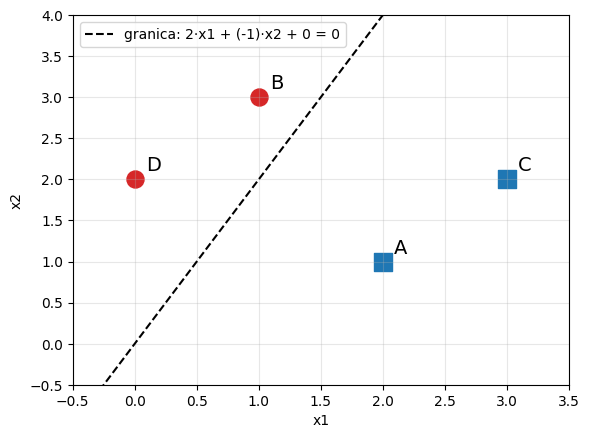

In [8]:
x1 = np.linspace(-0.5, 3.5, 2)
x2 = -(p.w_[0] * x1 + p.b_) / p.w_[1]          # prosta z = 0

plt.plot(x1, x2, "k--", label=f"granica: {p.w_[0]:.0f}·x1 + ({p.w_[1]:.0f})·x2 + {p.b_:.0f} = 0")
for nazwa, (a, b), klasa in zip("ABCD", X_kartka, y_kartka):
    plt.scatter(a, b, s=150, color="tab:blue" if klasa else "tab:red", marker="s" if klasa else "o")
    plt.annotate(nazwa, (a, b), xytext=(8, 6), textcoords="offset points", fontsize=14)
plt.xlim(-0.5, 3.5); plt.ylim(-0.5, 4); plt.grid(alpha=0.3)
plt.xlabel("x1"); plt.ylabel("x2"); plt.legend(); plt.show()

**Pytanie 1.** Po aktualizacji na punkcie B punkt C ma $z = -10$, czyli jest bardzo źle sklasyfikowany (zobacz wydruk). Co to mówi o sposobie, w jaki uczy się perceptron?

✍️ **Twoja odpowiedź:**
Perceptron uczy się online, po jednym punkcie naraz, bez patrzenia na całość. Poprawiając wagi pod bieżący błąd, może zepsuć klasyfikację punktów, które wcześniej działały dobrze. Dopiero po wielu epokach próbuje znaleźć kompromis dla wszystkich.

## 3. Dane: kwiaty irysa

Zbiór Iris zawiera pomiary 150 kwiatów z trzech gatunków: setosa (kwiaty 0–49), versicolor (50–99) i virginica (100–149). Na początek bierzemy:
- **dwa gatunki**: setosa (klasa 0) i versicolor (klasa 1), czyli pierwsze 100 kwiatów,
- **dwie cechy**: długość działki kielicha (kolumna 0) i długość płatka (kolumna 2).

Dwie cechy wybieramy po to, żeby wszystko dało się narysować na płaszczyźnie.

Kształt X: (100, 2)  Liczba przykładów w klasach: [50 50]


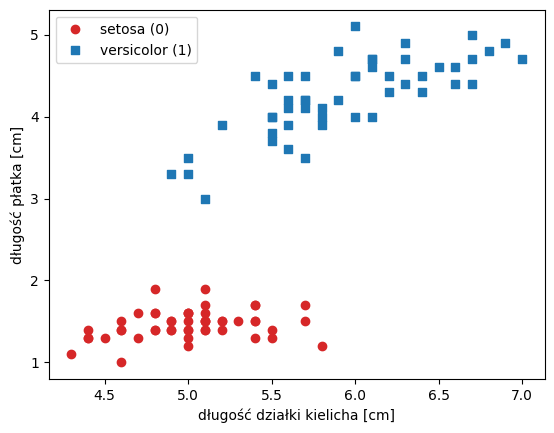

In [9]:
iris = load_iris()
X = iris.data[:100][:, [0, 2]]               # 100 kwiatów, cechy: działka, płatek [cm]
y = (iris.target[:100] == 1).astype(int)      # setosa -> 0, versicolor -> 1

print("Kształt X:", X.shape, " Liczba przykładów w klasach:", np.bincount(y))

plt.scatter(X[y == 0, 0], X[y == 0, 1], color="tab:red", marker="o", label="setosa (0)")
plt.scatter(X[y == 1, 0], X[y == 1, 1], color="tab:blue", marker="s", label="versicolor (1)")
plt.xlabel("długość działki kielicha [cm]")
plt.ylabel("długość płatka [cm]")
plt.legend(loc="upper left")
plt.show()

Funkcja pomocnicza do rysowania **regionów decyzyjnych**: koloruje każdy punkt płaszczyzny według tego, jaką klasę przewiduje model. Granica między kolorami to granica decyzyjna. Nie musisz jej modyfikować.

In [10]:
def plot_decision_regions(X, y, model, resolution=0.02, ax=None, title=None, etykiety=("klasa 0", "klasa 1")):
    ax = ax or plt.gca()
    cmap = ListedColormap(["tab:red", "tab:blue"])
    x1_min, x1_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    x2_min, x2_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx1, xx2 = np.meshgrid(np.arange(x1_min, x1_max, resolution),
                           np.arange(x2_min, x2_max, resolution))
    siatka = np.array([xx1.ravel(), xx2.ravel()]).T          # wszystkie punkty siatki
    Z = model.predict(siatka).reshape(xx1.shape)             # klasa dla każdego punktu
    ax.contourf(xx1, xx2, Z, alpha=0.25, cmap=cmap)
    for klasa, kolor, marker in [(0, "tab:red", "o"), (1, "tab:blue", "s")]:
        ax.scatter(X[y == klasa, 0], X[y == klasa, 1], c=kolor, marker=marker,
                   edgecolor="black", label=etykiety[klasa])
    ax.set_xlim(x1_min, x1_max); ax.set_ylim(x2_min, x2_max)
    if title: ax.set_title(title)
    ax.legend(loc="upper left")

## 4. Uczymy perceptron na Iris

### Zadanie 2
Naucz perceptron (`eta=0.1`, `n_iter=10`) na danych `X`, `y`. Następnie narysuj obok siebie:
1. liczbę pomyłek w każdej epoce (atrybut `errors_`),
2. regiony decyzyjne (funkcja `plot_decision_regions`).

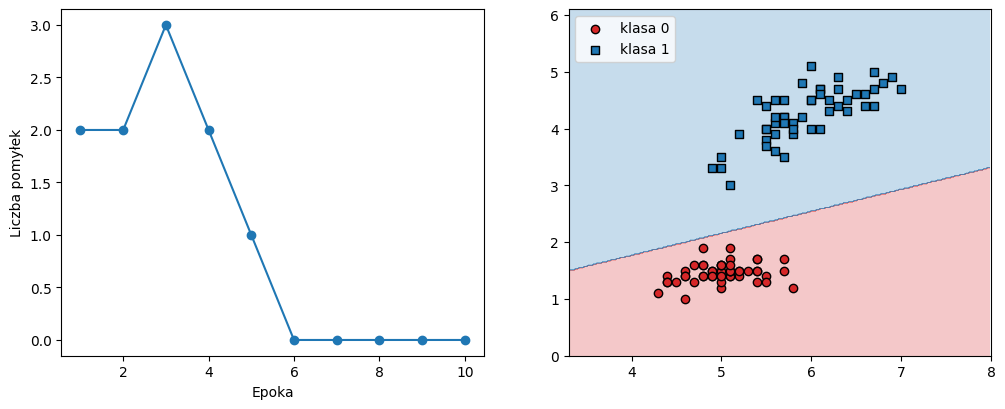

In [11]:
# TODO: utwórz perceptron i naucz go na X, y
ppn = Perceptron(eta=0.1, n_iter=10).fit(X, y)

fig, axs = plt.subplots(1, 2, figsize=(12, 4.5))
# TODO: na axs[0] wykres liczby pomyłek w kolejnych epokach
axs[0].plot(range(1, len(ppn.errors_) + 1), ppn.errors_, marker="o")
axs[0].set_xlabel("Epoka")
axs[0].set_ylabel("Liczba pomyłek")
# TODO: na axs[1] regiony decyzyjne: plot_decision_regions(X, y, ppn, ax=axs[1])
plot_decision_regions(X, y, ppn, ax=axs[1])
plt.show()

**Pytanie 2.** Po ilu epokach perceptron przestał się mylić? Czy granica decyzyjna leży „w środku” między klasami, czy blisko jednej z nich? Dlaczego perceptronowi jest wszystko jedno, gdzie dokładnie leży granica?

✍️ **Twoja odpowiedź:**
Perceptron przestał się mylić po 6. epoce. Granica nie leży idealnie pośrodku, tylko dość blisko jednej z klas. Jest mu to obojętne, bo jego jedynym celem jest brak błędów ($e = 0$) w momencie gdy znajdzie jakąkolwiek prostą poprawnie oddzielającą punkty, aktualizacje wag ustają i model się zatrzymuje, nie szukając optymalnego odstępu

## 5. Eksperyment: czy $\eta$ ma znaczenie?

### 5a. Najpierw kartka

Policz jeszcze raz przykład z kartki, ale z $\eta = 0.5$. Porównaj wydruk z wydrukiem dla $\eta = 1$ z punktu 2: co się zmieniło, a co nie?

In [ ]:
p_half = Perceptron(eta=0.5, n_iter=2, w_init="zeros", verbose=True).fit(X_kartka, y_kartka)

epoka 1 | x=[2. 1.] y=1 | w=[0. 0.] b= 0.00 | z=  0.00 ŷ=1 | update=+0.00
epoka 1 | x=[1. 3.] y=0 | w=[0. 0.] b= 0.00 | z=  0.00 ŷ=1 | update=-0.50
epoka 1 | x=[3. 2.] y=1 | w=[-0.5 -1.5] b=-0.50 | z= -5.00 ŷ=0 | update=+0.50
epoka 1 | x=[0. 2.] y=0 | w=[ 1.  -0.5] b= 0.00 | z= -1.00 ŷ=0 | update=+0.00
--- koniec epoki 1: pomyłek 2, w=[ 1.  -0.5], b=0.00
epoka 2 | x=[2. 1.] y=1 | w=[ 1.  -0.5] b= 0.00 | z=  1.50 ŷ=1 | update=+0.00
epoka 2 | x=[1. 3.] y=0 | w=[ 1.  -0.5] b= 0.00 | z= -0.50 ŷ=0 | update=+0.00
epoka 2 | x=[3. 2.] y=1 | w=[ 1.  -0.5] b= 0.00 | z=  2.00 ŷ=1 | update=+0.00
epoka 2 | x=[0. 2.] y=0 | w=[ 1.  -0.5] b= 0.00 | z= -1.00 ŷ=0 | update=+0.00
--- koniec epoki 2: pomyłek 0, w=[ 1.  -0.5], b=0.00


**Pytanie 3.** Porównaj kolumny `z`, `ŷ` i końcowe wagi dla $\eta = 1$ i $\eta = 0.5$. Czy granica decyzyjna jest inna?

✍️ **Twoja odpowiedź:**
Dla $\eta = 0.5$ wszystkie wartości $z$ oraz końcowe wagi i bias są dokładnie o połowę mniejsze niż dla $\eta = 1$. Wartości $\hat{y}$ są identyczne, bo znak $z$ się nie zmienił. Granica decyzyjna ($w_1 x_1 + w_2 x_2 + b = 0$) jest dokładnie tą samą prostą, przeskalowanie wag przez dodatnią liczbę nie zmienia położenia prostej

### 5b. Teraz Iris

Naucz perceptron na Iris z czterema wartościami $\eta \in \{0.0001,\ 0.01,\ 0.1,\ 1\}$, **startując od zerowych wag** (`w_init="zeros"`).

**Przewiduję:** przy którym $\eta$ perceptron nauczy się najszybciej (najmniej epok do zera pomyłek)?

✍️ **Moje przewidywanie (zapisz przed uruchomieniem):**
Nauczy się dokładnie w tylu samych epokach dla każdego $\eta$ – $\eta$ nie ma żadnego wpływu na szybkość nauki przy zerowych wagach startowych.  

η = 0.0001  pomyłki: [2, 2, 3, 2, 1, 0, 0, 0, 0, 0]   w/η = [-3.4  9.1],  b/η = -2.00
η = 0.01    pomyłki: [2, 2, 3, 2, 1, 0, 0, 0, 0, 0]   w/η = [-3.4  9.1],  b/η = -2.00
η = 0.1     pomyłki: [2, 2, 3, 2, 1, 0, 0, 0, 0, 0]   w/η = [-3.4  9.1],  b/η = -2.00
η = 1.0     pomyłki: [2, 2, 3, 2, 1, 0, 0, 0, 0, 0]   w/η = [-3.4  9.1],  b/η = -2.00


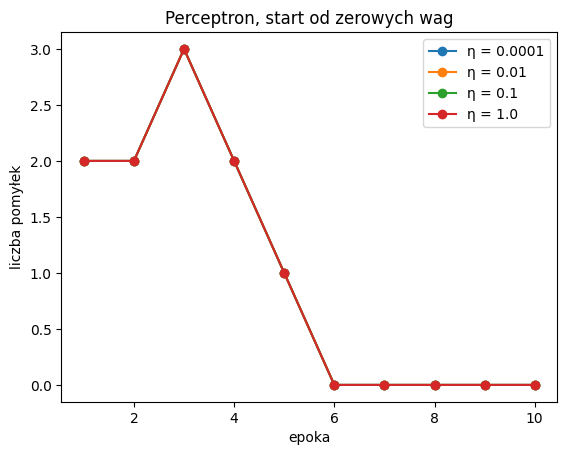

In [ ]:
etas = [0.0001, 0.01, 0.1, 1.0]

for eta in etas:
    p = Perceptron(eta=eta, n_iter=10, w_init="zeros").fit(X, y)
    plt.plot(range(1, 11), p.errors_, marker="o", label=f"η = {eta}")
    print(f"η = {eta:<7} pomyłki: {p.errors_}   w/η = {p.w_ / eta},  b/η = {p.b_ / eta:.2f}")

plt.xlabel("epoka"); plt.ylabel("liczba pomyłek")
plt.title("Perceptron, start od zerowych wag"); plt.legend(); plt.show()

Wszystkie linie leżą na sobie. Spójrz na kolumnę `w/η`: jest **identyczna** dla każdego $\eta$.

**Pytanie 4.** Wyjaśnij, dlaczego przy zerowych wagach startowych $\eta$ nie ma wpływu na uczenie perceptronu. Wskazówka: od czego zależy predykcja $\hat{y}$ — od wartości $z$ czy tylko od jej znaku?

✍️ **Twoja odpowiedź:**
Predykcja $\hat{y}$ zależy tylko od znaku $z$, a nie od jego wartości. Przy wagach startowych równych zero, wagi po każdym kroku są po prostu pomnożone przez $\eta$. Ponieważ $\eta > 0$, znak $z$ pozostaje identyczny dla każdej wartości $\eta$, więc model podejmuje te same decyzje i robi błędy w dokładnie tych samych momentach.

### 5c. Losowe wagi startowe

To samo, ale z **małymi losowymi wagami startowymi** (domyślne `w_init="random"`, jak u Raschki; wagi są losowane z rozkładu normalnego o odchyleniu 0.01).

η = 0.0001  pomyłki: [34, 16, 13, 11, 10, 8, 6, 5, 5, 5]
η = 0.01    pomyłki: [2, 2, 3, 1, 0, 0, 0, 0, 0, 0]
η = 0.1     pomyłki: [2, 2, 3, 2, 1, 0, 0, 0, 0, 0]
η = 1.0     pomyłki: [2, 2, 3, 2, 1, 0, 0, 0, 0, 0]


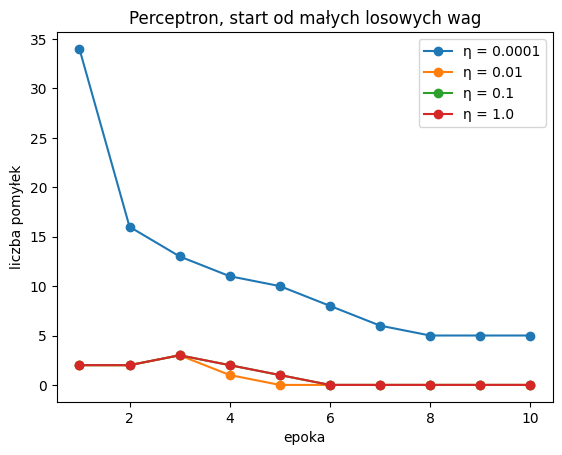

In [ ]:
for eta in etas:
    p = Perceptron(eta=eta, n_iter=10, w_init="random").fit(X, y)
    plt.plot(range(1, 11), p.errors_, marker="o", label=f"η = {eta}")
    print(f"η = {eta:<7} pomyłki: {p.errors_}")
plt.xlabel("epoka"); plt.ylabel("liczba pomyłek")
plt.title("Perceptron, start od małych losowych wag"); plt.legend(); plt.show()

**Pytanie 5.** Dlaczego teraz najmniejsze $\eta = 0.0001$ uczy się wyraźnie wolniej, a pozostałe prawie tak samo?

✍️ **Twoja odpowiedź:**
Wagi startowe nie są zerami, tylko małymi losowymi liczbami z przedziału rzędu 0.01. Przy $\eta = 0.0001$ poprawka wag ($\Delta w = \eta \cdot e \cdot x$) jest mikroskopijna w porównaniu z wagami losowymi, więc model potrzebuje wielu epok, żeby w ogóle przebić ten początkowy szum. Przy większych $\eta$ poprawki natychmiast dominują nad wagami losowymi.

## 6. Gdy klas nie da się rozdzielić prostą

Weźmy teraz inną parę gatunków: **versicolor** (klasa 0) i **virginica** (klasa 1), czyli kwiaty o indeksach 50–149, z tymi samymi dwiema cechami.

**Przewiduję:** po ilu epokach perceptron przestanie się mylić?

✍️ **Moje przewidywanie (zapisz przed uruchomieniem):**
Perceptron nigdy nie przestanie się mylić, ponieważ te dwie klasy nakładają się na siebie i nie da się ich rozdzielić jedną prostą linią.

### Zadanie 3
1. Utwórz `X2` (kwiaty 50–149, kolumny 0 i 2) i `y2` (1 dla virginica, 0 dla versicolor). Wskazówka: virginica ma w `iris.target` wartość 2.
2. **Przetasuj dane** (kod jest podany). W zbiorze Iris kwiaty są posortowane według gatunku: najpierw 50 versicolor, potem 50 virginica. Bez tasowania perceptron widzi 50 kwiatów jednej klasy z rzędu i dopasowuje się tylko do ostatnio oglądanej.
3. Naucz perceptron (`eta=0.1`, `n_iter=30`) i narysuj liczbę pomyłek w epokach oraz regiony decyzyjne.
4. Policz, ile pomyłek robi **nauczony model** (po ostatniej epoce) na całym zbiorze: `(ppn2.predict(X2) != y2).sum()`.

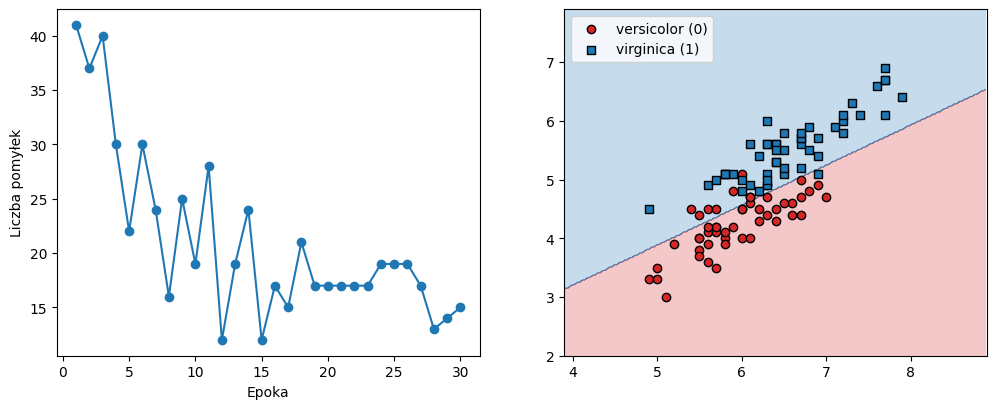

Liczba pomyłek modelu: 10


In [12]:
iris = load_iris()
X2 = iris.data[50:150][:, [0, 2]]
y2 = (iris.target[50:150] == 2).astype(int)

idx = np.random.RandomState(0).permutation(len(y2))
X2, y2 = X2[idx], y2[idx]

ppn2 = Perceptron(eta=0.1, n_iter=30).fit(X2, y2)

fig, axs = plt.subplots(1, 2, figsize=(12, 4.5))
axs[0].plot(range(1, len(ppn2.errors_) + 1), ppn2.errors_, marker="o")
axs[0].set_xlabel("Epoka")
axs[0].set_ylabel("Liczba pomyłek")

plot_decision_regions(X2, y2, ppn2, ax=axs[1], etykiety=("versicolor (0)", "virginica (1)"))
plt.show()

print(f"Liczba pomyłek modelu: {(ppn2.predict(X2) != y2).sum()}")

Sprawdźmy jeszcze, co się dzieje z wagami, gdy uczymy dłużej.

In [13]:
for n in [10, 20, 30, 100]:
    p = Perceptron(eta=0.1, n_iter=n).fit(X2, y2)
    print(f"po {n:>3} epokach: w = {p.w_},  b = {p.b_:5.2f},  "
          f"pomyłki w ostatniej epoce: {p.errors_[-1]:>2},  pomyłki modelu: {(p.predict(X2) != y2).sum()}")

po  10 epokach: w = [-3.474  5.024],  b = -2.00,  pomyłki w ostatniej epoce: 19,  pomyłki modelu: 10
po  20 epokach: w = [-5.124  7.114],  b = -3.00,  pomyłki w ostatniej epoce: 17,  pomyłki modelu: 10
po  30 epokach: w = [-5.614  8.234],  b = -3.90,  pomyłki w ostatniej epoce: 15,  pomyłki modelu: 10
po 100 epokach: w = [-7.124 11.064],  b = -9.50,  pomyłki w ostatniej epoce: 11,  pomyłki modelu: 8


**Pytanie 6.** Czy perceptron kiedykolwiek przestaje się mylić? Co dzieje się z wagami? Co to oznacza dla „wyniku” uczenia? Dlaczego liczba pomyłek *w trakcie* epoki (`errors_`) jest inna niż liczba pomyłek *nauczonego modelu*?

✍️ **Twoja odpowiedź:**
Nie, perceptron nigdy nie przestanie się mylić, bo te klasy nachodzą na siebie i są liniowo nierozerwalne.
Wagi i bias bez przerwy się zmieniają i kręcą w kółko przy każdym błędnym punkcie.
To oznacza, że wynik końcowy jest dziełem przypadku i zależy tylko od tego, na której epoce zatrzymamy pętlę.
Liczba pomyłek w trakcie epoki różni się od końcowej liczby pomyłek modelu, bo w trakcie epoki wagi są na bieżąco poprawiane przy każdym punkcie, a model sprawdzamy na zamrożonych, ostatecznych wagach.

## 7. XOR: czego jeden neuron nie potrafi

Funkcja **XOR** („albo, albo”) daje 1, gdy *dokładnie jedno* z dwóch wejść jest równe 1:

| $x_1$ | $x_2$ | AND | OR | **XOR** |
|---|---|---|---|---|
| 0 | 0 | 0 | 0 | **0** |
| 1 | 0 | 0 | 1 | **1** |
| 0 | 1 | 0 | 1 | **1** |
| 1 | 1 | 1 | 1 | **0** |

### Zadanie 4
1. Utwórz `X_log` (4 punkty z tabeli) oraz etykiety `y_and`, `y_or`, `y_xor`.
2. Naucz perceptron (`eta=0.1`, `n_iter=20`, `w_init="zeros"`) osobno dla AND, OR i XOR.
3. Wypisz liczbę pomyłek w epokach dla każdej funkcji i narysuj ją na jednym wykresie.

**Przewiduję:** których funkcji perceptron się nauczy?

✍️ **Moje przewidywanie (zapisz przed uruchomieniem):**
Perceptron bez problemu nauczy się funkcji AND i OR, bo da się je rozdzielić prostą linią. Nie nauczy się jednak XOR, ponieważ punkty tej klasy są ułożone naprzemiennie na ukos i nie ma fizycznej możliwości oddzielenia ich pojedynczą prostą.

AND pomyłki: [2, 3, 3, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
OR pomyłki:  [2, 2, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
XOR pomyłki: [3, 3, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4]


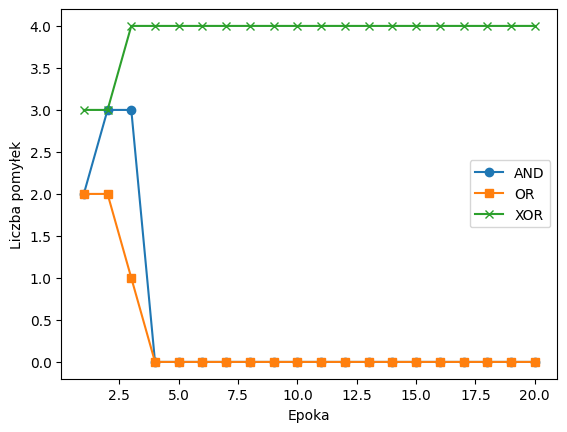

In [14]:
X_log = np.array([[0, 0], [1, 0], [0, 1], [1, 1]], dtype=float)
y_and = np.array([0, 0, 0, 1])
y_or  = np.array([0, 1, 1, 1])
y_xor = np.array([0, 1, 1, 0])

ppn_and = Perceptron(eta=0.1, n_iter=20, w_init="zeros").fit(X_log, y_and)
ppn_or  = Perceptron(eta=0.1, n_iter=20, w_init="zeros").fit(X_log, y_or)
ppn_xor = Perceptron(eta=0.1, n_iter=20, w_init="zeros").fit(X_log, y_xor)

print(f"AND pomyłki: {ppn_and.errors_}")
print(f"OR pomyłki:  {ppn_or.errors_}")
print(f"XOR pomyłki: {ppn_xor.errors_}")

plt.plot(range(1, 21), ppn_and.errors_, marker="o", label="AND")
plt.plot(range(1, 21), ppn_or.errors_, marker="s", label="OR")
plt.plot(range(1, 21), ppn_xor.errors_, marker="x", label="XOR")
plt.xlabel("Epoka")
plt.ylabel("Liczba pomyłek")
plt.legend()
plt.show()

Zobacz krok po kroku, co robi perceptron na XOR w pierwszych trzech epokach:

In [15]:
_ = Perceptron(eta=0.1, n_iter=3, w_init="zeros", verbose=True).fit(X_log, np.array([0, 1, 1, 0]))

epoka 1 | x=[0. 0.] y=0 | w=[0. 0.] b= 0.00 | z=  0.00 ŷ=1 | update=-0.10
epoka 1 | x=[1. 0.] y=1 | w=[0. 0.] b=-0.10 | z= -0.10 ŷ=0 | update=+0.10
epoka 1 | x=[0. 1.] y=1 | w=[0.1 0. ] b= 0.00 | z=  0.00 ŷ=1 | update=+0.00
epoka 1 | x=[1. 1.] y=0 | w=[0.1 0. ] b= 0.00 | z=  0.10 ŷ=1 | update=-0.10
--- koniec epoki 1: pomyłek 3, w=[ 0.  -0.1], b=-0.10
epoka 2 | x=[0. 0.] y=0 | w=[ 0.  -0.1] b=-0.10 | z= -0.10 ŷ=0 | update=+0.00
epoka 2 | x=[1. 0.] y=1 | w=[ 0.  -0.1] b=-0.10 | z= -0.10 ŷ=0 | update=+0.10
epoka 2 | x=[0. 1.] y=1 | w=[ 0.1 -0.1] b= 0.00 | z= -0.10 ŷ=0 | update=+0.10
epoka 2 | x=[1. 1.] y=0 | w=[0.1 0. ] b= 0.10 | z=  0.20 ŷ=1 | update=-0.10
--- koniec epoki 2: pomyłek 3, w=[ 0.  -0.1], b=0.00
epoka 3 | x=[0. 0.] y=0 | w=[ 0.  -0.1] b= 0.00 | z=  0.00 ŷ=1 | update=-0.10
epoka 3 | x=[1. 0.] y=1 | w=[ 0.  -0.1] b=-0.10 | z= -0.10 ŷ=0 | update=+0.10
epoka 3 | x=[0. 1.] y=1 | w=[ 0.1 -0.1] b= 0.00 | z= -0.10 ŷ=0 | update=+0.10
epoka 3 | x=[1. 1.] y=0 | w=[0.1 0. ] b= 0.10 | z

**Pytanie 7.** AND i OR działają, XOR nie. Narysuj na kartce 4 punkty XOR i spróbuj poprowadzić jedną prostą, która oddzieli klasę 1 od klasy 0. Dlaczego się nie da? Co widać w wydruku powyżej: co dzieje się z wagami z epoki na epokę?

✍️ **Twoja odpowiedź:**
Klasy 1 i 0 w XOR leżą naprzemiennie na ukos (punkty (0,1) i (1,0) mają klasę 1, a (0,0) i (1,1) klasę 0). Nie da się narysować jednej prostej linii, która oddzieliłaby te dwie grupy bez przecięcia którejś z nich.
W wydruku krok po kroku widać, że wagi i bias wpadają w nieskończoną pętlę – kręcą się w kółko i ciągle powtarzają te same wartości, przez co model co chwilę psuje to, co przed chwilą próbował poprawić.

## 8. Podsumowanie

Odpowiedz krótko własnymi słowami (kliknij dwukrotnie, żeby edytować):

1. **Co oznacza geometrycznie zbiór punktów, dla których $z = 0$?**
Jest to linia prosta (granica decyzyjna), która oddziela od siebie dwie klasy punktów na wykresie.

2. **Kiedy perceptron zmienia wagi, a kiedy nie?**
Zmienia wagi tylko wtedy, gdy popełni błąd klasyfikacji (gdy predykcja różni się od prawdziwej etykiety). Nie zmienia ich, gdy trafi idealnie.

3. **Dlaczego przy starcie od zera $eta$ (lub $\eta$) nie zmienia granicy?**
Bo $\eta$ skaluje jedynie długość wektora wag, a nie jego kierunek. Znak wartości $z$ się nie zmienia, więc granica decyzyjna (miejsce gdzie $z=0$) ląduje w dokładnie tym samym miejscu.

4. **Kiedy perceptron gwarantuje, że się zatrzyma?**
Tylko i wyłącznie wtedy, gdy dane są liniowo sterowalne (da się je idealnie rozdzielić jedną prostą linią).

5. **Dlaczego jeden neuron nie nauczy się XOR?**
Ponieważ klas w problemie XOR nie da się rozdzielić pojedynczą prostą linią – wymagają one przynajmniej dwóch linii cięcia.

---
## Zadanie dodatkowe (na ocenę 4/5)

Dla pary versicolor/virginica wybierz **inne dwie cechy**: długość i szerokość płatka (kolumny 2 i 3). Użyj tej samej kolejności co w zadaniu 3, bo etykiety `y2` są już przetasowane:

```python
X3 = iris.data[50:][:, [2, 3]][idx]
```

Naucz perceptron przez 50 epok, narysuj regiony decyzyjne i liczbę pomyłek w epokach, policz pomyłki nauczonego modelu.
1. Czy z tymi cechami klasy dają się rozdzielić prostą? Czy perceptron się zatrzymuje? Ile pomyłek robi nauczony model w porównaniu z zadaniem 3?
2. Czy wybór cech jest częścią „uczenia”? Kto go dokonuje?

In [ ]:
# Zadanie dodatkowe — Twój kod